# Does where an answer sits pull the choice?

Nearly everyone reads the question and then looks first at the answer right below it -- the top
one -- and usually goes round from there, clockwise or anticlockwise. If where the eyes go shapes
what is chosen, the answer met first should be chosen more often whenever there is nothing better
to go on. Study 2's **no-knowledge** regime is that case: no paragraph, no answer, so a correct
answer is a guess. The regimes with knowledge, and Study 1, where everyone has read the paragraph,
are the comparisons.

**Why the tests need no model.** Both studies place the four answers at the four positions at
random. So the answer at any one position is a random one, and if position made no difference the
chosen answer would sit at each position one time in four -- exactly, whatever the answers are like
and however people differ. Each test re-draws the placement the way the design drew it and asks how
often chance looks as uneven as the data.

**The placement is drawn at two grains.** Study 2 shuffles every trial on its own. Study 1 shuffles
each item once per counterbalancing list, so the two people of a list who see an item see the same
order. The re-draws follow that (`data.UNIT_COLS`): trials that share an order move together.

**What "first reached" means here.** The order in which the four answers were first reached before
the decision (the final selection press). The first one is the first step of the participant's
starting strategy (`features/strategies.py`); the run checks that the two agree on every trial.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; run.py saves

import matplotlib.pyplot as plt
from IPython.display import display

from src.explorations.position_bias import plots as P
from src.explorations.position_bias import run as R

STUDIES = ["knowqa", "l1"]

## 1. The tables
*`run.compute`*

Every table, per study, with the settings `run.py` saves with (10,000 random re-placements per test,
and 2,000 participant resamples per model in Study 2, 1,000 in Study 1), so the numbers here are the
saved ones. Study 1 takes several minutes, most of it the resampling.

The printout is the list of randomisation tests per group. Study 1 has 25 trials with no decision
time or no look at an answer before it: they count in every test of where the choice went, but not
in anything that needs gaze, and each table says how many trials it had.

In [2]:
t = {key: R.compute(key) for key in STUDIES}

[cache] knowqa fixations: read knowqa_fixations__9aae2be11dda.pkl
knowqa: 1885 trials | fixations after the decision (left out of the models): 14,408 of 78,725 | cut at the press: 1,647
  trials the models cannot use: 0
knowqa: 1885 trials, 0 without gaze before a decision (in the choice tests, not the gaze analyses)
           subset                                                                  test  n_trials   value      p
     no knowledge                         chosen answer: at each position equally often       625     NaN 0.0009
     no knowledge                            chosen answer: at the top one time in four       625  0.3168 0.0001
     no knowledge                      wrong answer chosen: at the top one time in four       393  0.2952 0.0408
     no knowledge                    accuracy: the same wherever the correct answer sat       625  0.3712 0.0018
     no knowledge    accuracy: the same with the correct answer at the top as elsewhere       625  0.1491 0.0007
   

## 2. Was anything placed at the top more often than chance?
*`placement.placement_tests`, `placement.expected_shares`, `plots.plot_placement`*

Everything else rests on the placement being random, so first the check that it came out that way.
Counted over placements, not trials.

**What is plotted.**

* **Heatmaps:** for each group, the share of placements that put each kind of answer (A correct;
  B, C, D the wrong ones) at each position. One in four is even; red is more often, blue less.
* **Length:** the mean length of the answer placed at each position.
* **Others' choices:** how often *other* people chose the answer placed at each position -- people
  who saw the same item in another placement (Study 2: in the same regime). It tests whether answers
  that attract choices happened to land at the top. In Study 2 an item has only one or two people
  per regime, so this is coarse there; Study 1 has about eighteen.
* **Last panel:** the share of choices each position got (solid), against the share it would have
  got if people chose only by content -- by how often others chose each answer (dashed).

**What to look for.** A cell or line far from even, with a small p, would mean the placement leans.
The p values come from re-drawn placements, not the usual chi-squared test: since every placement
puts exactly one kind at each position, a kind-by-position table varies more than that test assumes,
and its p values come out too small. In the last panel, if the solid and dashed lines meet, what was
placed at each position explains the choices; a gap at the top that the dashed line does not share is
a pull towards the position itself.

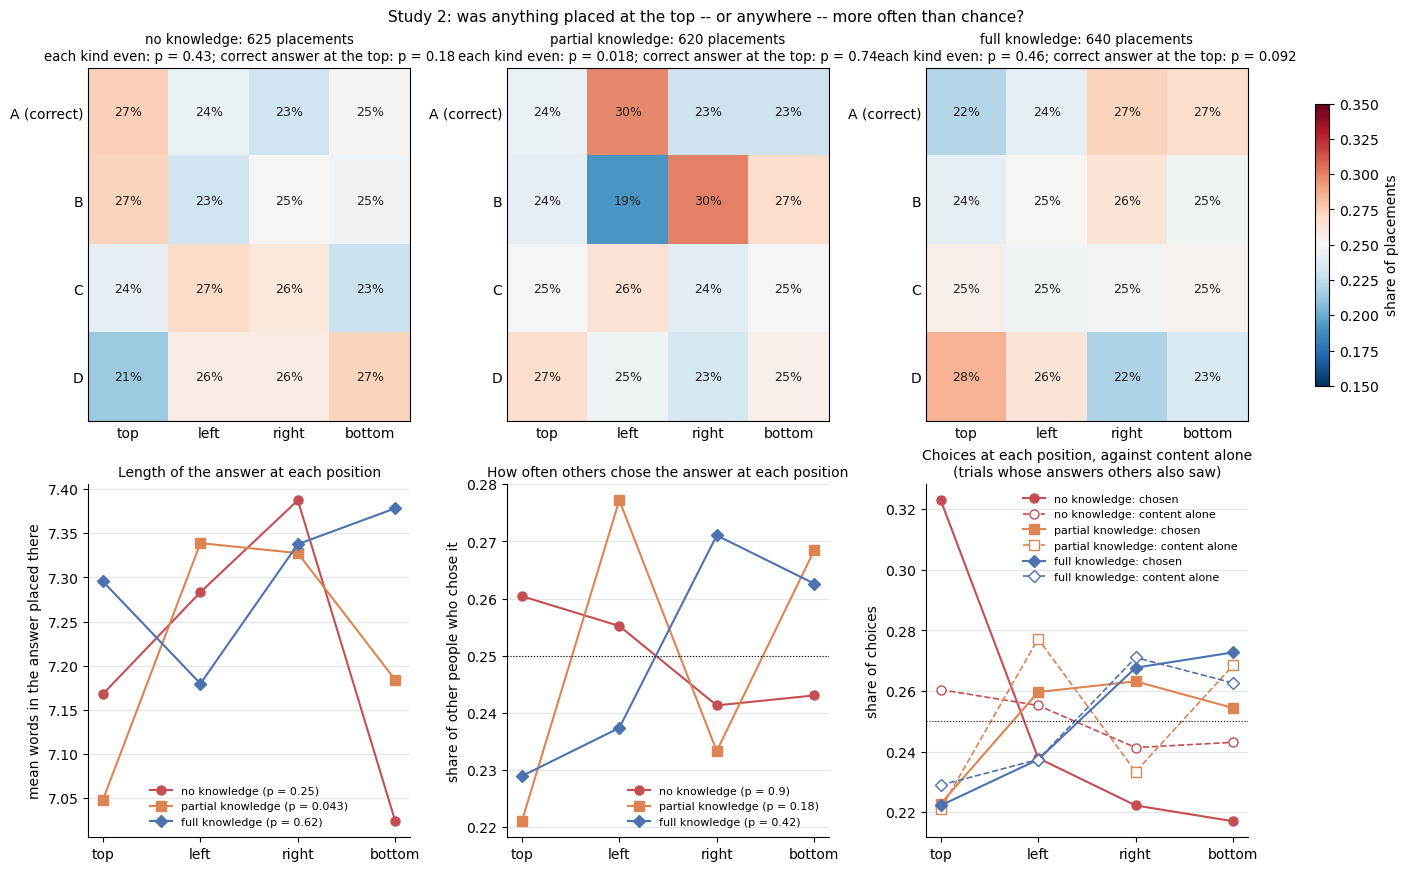

,subset,test,statistic,p,n_units,n_units_with_attractiveness,n_draws,seed
0,no knowledge,each kind at each position one time in four,12.1280,0.4274,625,576,10000,0
1,no knowledge,the correct answer at the top one time in four,0.0236,0.1813,625,576,10000,0
2,no knowledge,answers equally long at every position,1.1733,0.2480,625,576,10000,0
3,no knowledge,the top answer as long as the others,0.0020,0.9107,625,576,10000,0
4,no knowledge,answers others chose equally often at every po...,0.1493,0.8966,625,576,10000,0
5,no knowledge,the top answer chosen by others as often as th...,0.0104,0.6041,625,576,10000,0
6,partial knowledge,each kind at each position one time in four,26.1935,0.0185,620,570,10000,0
7,partial knowledge,the correct answer at the top one time in four,0.0065,0.7425,620,570,10000,0
8,partial knowledge,answers equally long at every position,2.4845,0.0429,620,570,10000,0
9,partial knowledge,the top answer as long as the others,0.0435,0.0240,620,570,10000,0


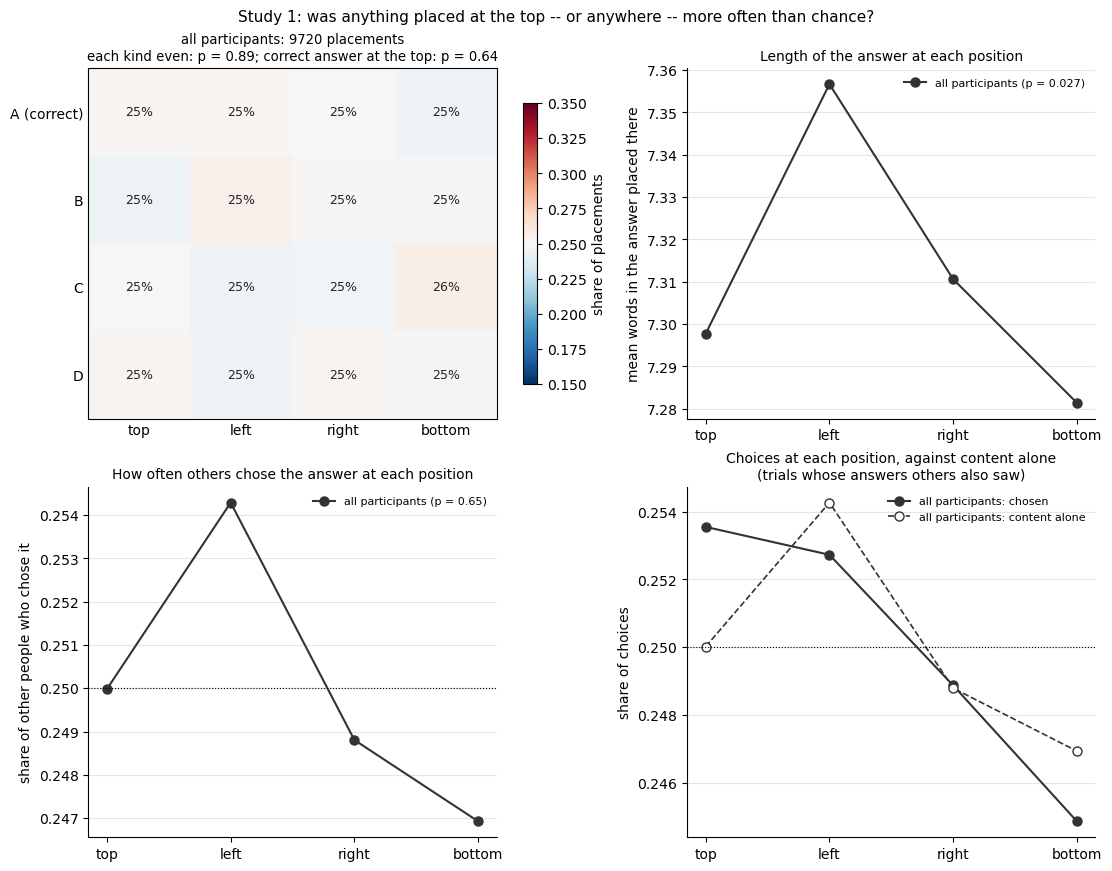

,subset,test,statistic,p,n_units,n_units_with_attractiveness,n_draws,seed
0,all participants,each kind at each position one time in four,5.8831,0.8856,9720,9720,10000,0
1,all participants,the correct answer at the top one time in four,0.0022,0.6368,9720,9720,10000,0
2,all participants,answers equally long at every position,2.5542,0.0268,9720,9720,10000,0
3,all participants,the top answer as long as the others,0.0043,0.3586,9720,9720,10000,0
4,all participants,answers others chose equally often at every po...,0.2846,0.6486,9720,9720,10000,0
5,all participants,the top answer chosen by others as often as th...,0.0000,0.9968,9720,9720,10000,0
6,hunters,each kind at each position one time in four,5.9385,0.8747,9719,9719,10000,0
7,hunters,the correct answer at the top one time in four,0.0022,0.6220,9719,9719,10000,0
8,hunters,answers equally long at every position,2.5545,0.0238,9719,9719,10000,0
9,hunters,the top answer as long as the others,0.0043,0.3512,9719,9719,10000,0


In [3]:
for key in STUDIES:
    P.plot_placement(t[key], key)
    plt.show()
    display(t[key]["placement_tests"].round(4))

## 3. Where the choices went, and where the correct answer sat
*`choice.randomisation_tests`, `plots.plot_choices`*

One row per group.

* **(a)** the position of the chosen answer;
* **(b)** on wrong trials, the position of the wrong answer chosen;
* **(c)** accuracy by where the correct answer sat;
* **(d)** accuracy by when the scan first reached the correct answer.

**What to look for.** A pull towards the top shows three ways at once: more choices at the top (a),
more wrong choices at the top (b), and more right answers when the correct one happens to be at the
top (c). (d) has no p value: the order is the participant's, not the design's, so it is not
randomised.

**Read (d) with knowledge with care.** Someone who knows the answer may decide soon after reaching
it, so when the correct answer is reached says something about the search, not only about a bias.

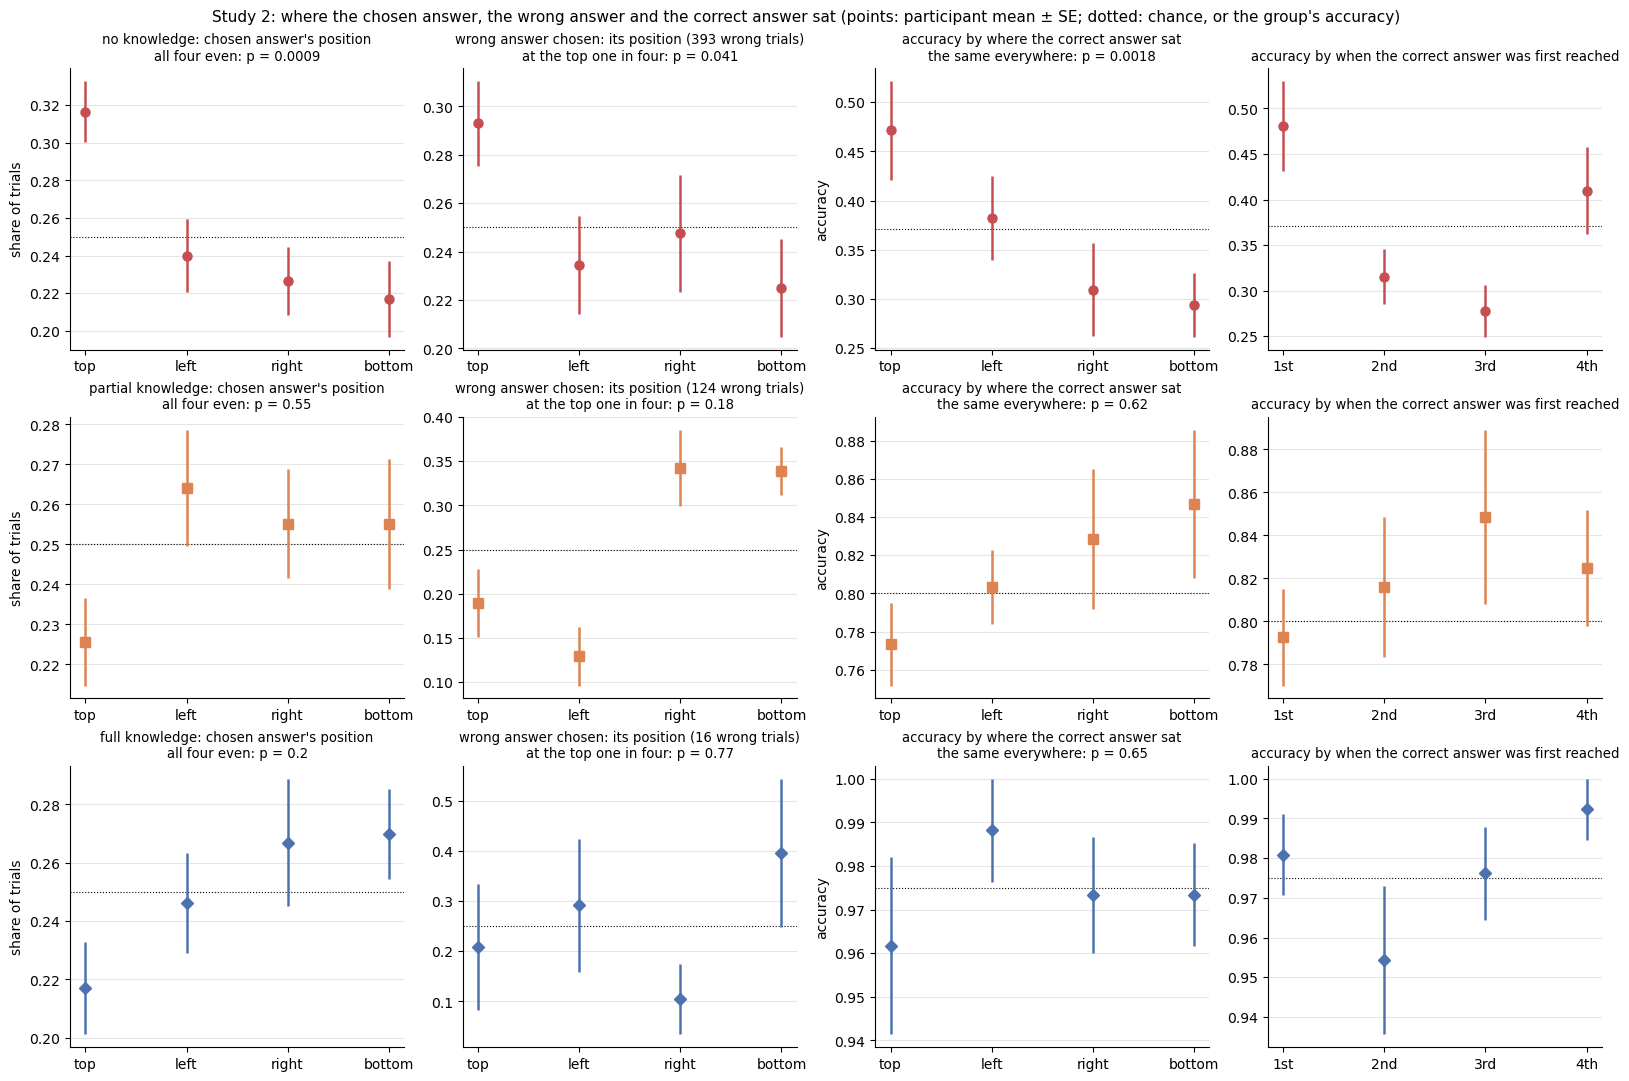

,subset,test,n_trials,value,statistic,p,n_draws,seed
0,no knowledge,chosen answer: at each position equally often,625,NaN,15.5952,0.0009,10000,0
1,no knowledge,chosen answer: at the top one time in four,625,0.3168,0.0668,0.0001,10000,0
2,no knowledge,wrong answer chosen: at the top one time in four,393,0.2952,0.0452,0.0408,10000,0
3,no knowledge,accuracy: the same wherever the correct answer...,625,0.3712,15.2498,0.0018,10000,0
4,no knowledge,accuracy: the same with the correct answer at ...,625,0.1491,0.1491,0.0007,10000,0
5,no knowledge,chosen answer: at the participant's usual firs...,625,0.3184,0.0684,0.0003,10000,0
6,no knowledge,first look: on each kind of answer equally often,625,NaN,4.4976,0.2217,10000,0
7,partial knowledge,chosen answer: at each position equally often,620,NaN,2.0903,0.5545,10000,0
8,partial knowledge,chosen answer: at the top one time in four,620,0.2258,0.0242,0.1757,10000,0
9,partial knowledge,wrong answer chosen: at the top one time in four,124,0.1935,0.0565,0.1753,10000,0


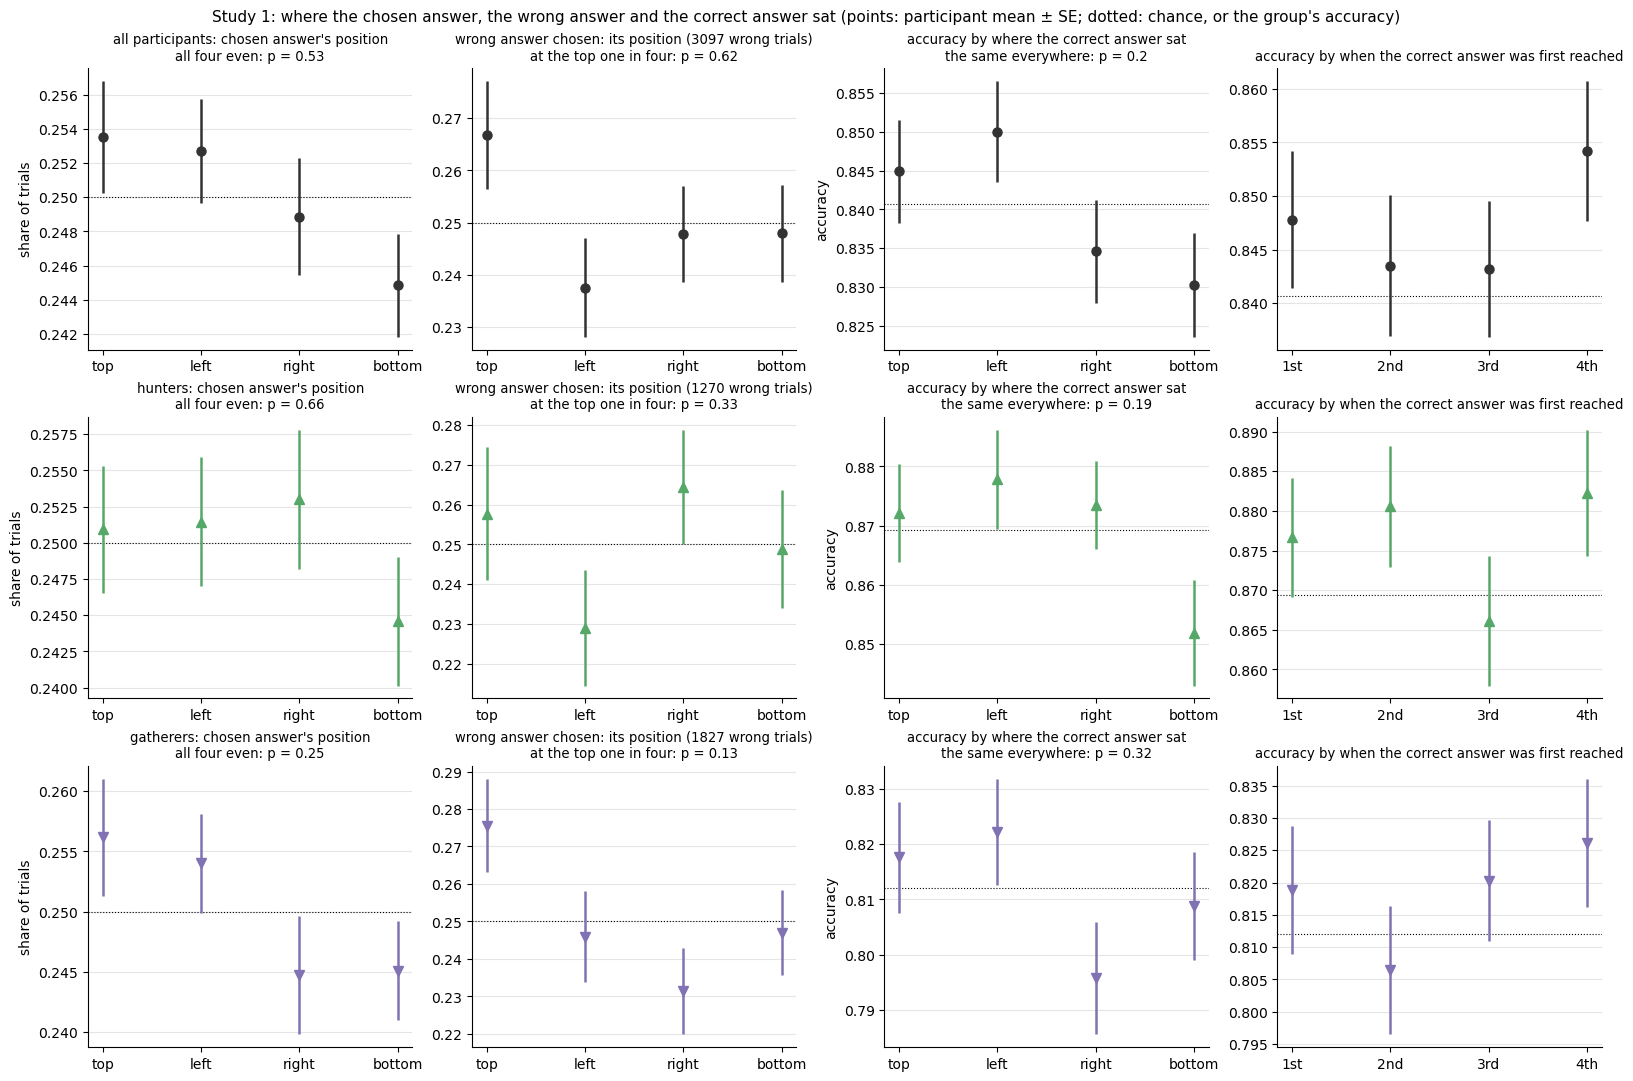

,subset,test,n_trials,value,statistic,p,n_draws,seed
0,all participants,chosen answer: at each position equally often,19436,NaN,3.7156,0.5266,10000,0
1,all participants,chosen answer: at the top one time in four,19436,0.2536,0.0036,0.3848,10000,0
2,all participants,wrong answer chosen: at the top one time in four,3097,0.2541,0.0041,0.6212,10000,0
3,all participants,accuracy: the same wherever the correct answer...,19436,0.8407,5.2356,0.1970,10000,0
4,all participants,accuracy: the same with the correct answer at ...,19436,0.0055,0.0055,0.3906,10000,0
5,all participants,chosen answer: at the participant's usual firs...,19436,0.2515,0.0015,0.7040,10000,0
6,all participants,first look: on each kind of answer equally often,19411,NaN,0.9266,0.9140,10000,0
7,hunters,chosen answer: at each position equally often,9719,NaN,1.6161,0.6613,10000,0
8,hunters,chosen answer: at the top one time in four,9719,0.2510,0.0010,0.8402,10000,0
9,hunters,wrong answer chosen: at the top one time in four,1270,0.2378,0.0122,0.3347,10000,0


In [4]:
for key in STUDIES:
    P.plot_choices(t[key], key)
    plt.show()
    display(t[key]["choice_tests"].round(4))

## 4. Guesses and the opening scan
*`plots.plot_guesses`*

Study 2's no-knowledge regime alone, with each participant as a dot.

* **(a)** where the guessed answer sat;
* **(b)** when it was first reached, on the trials that reached all four answers before the
  decision -- an answer not reached by then can hardly be chosen, so those trials would make "late"
  partly mean "never seen";
* **(c)** each position's share of the answer gaze before the decision, for the answer guessed and
  the ones not guessed;
* **(d)** how often a guess was right, by where the correct answer sat.

**What to look for.** In (b), a fall from the first answer reached to the second and third is a
primacy effect; a rise again at the fourth, a small recency one. In (c), the guessed answer draws
more gaze everywhere, because people look at what they are about to choose; the line for the answers
*not* guessed shows where gaze goes apart from that.

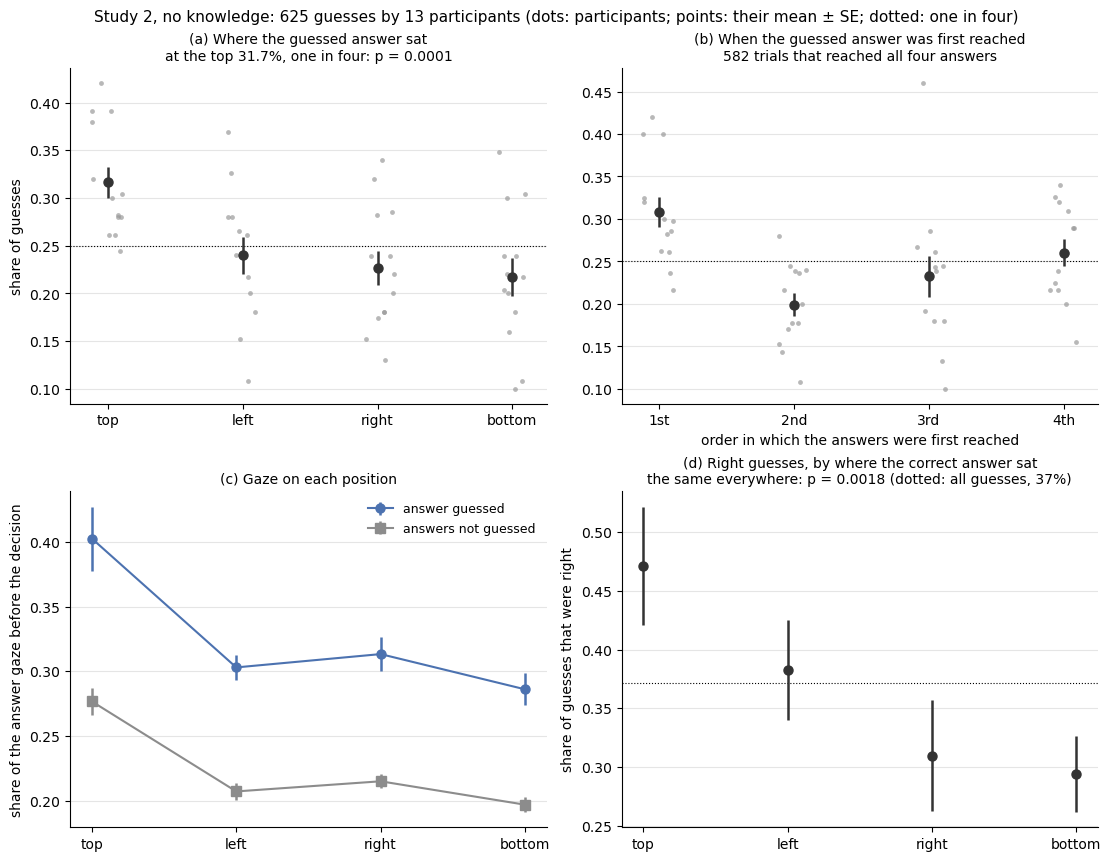

In [5]:
P.plot_guesses(t["knowqa"])
plt.show()

## 5. How big, over and above the kind of answer
*`choice.choice_models`, `plots.plot_models`*

Conditional logits: on each trial, the chosen answer against the other three, with the kind of answer
(A-D) always in the model, so an effect of position or order is over and above what kind of answer
sat there. Odds ratios with 95% intervals from resampling participants.

* **Position** -- left, right and bottom against the top.
* **Position with length and others' choices** -- the same, with each answer's length and how often
  others chose it in the model too: the strictest control for what was placed where.
* **Order** -- reached 2nd, 3rd, 4th against reached first, on trials that reached all four.
* **Top and first reached together** -- whether the two can be told apart. Since nearly every scan
  starts at the top, they pick out nearly the same answers, and wide intervals on both mean the data
  cannot say which of the two matters.
* **Length** -- an answer twice as long as another.

Study 2's full-knowledge regime is left out: almost every choice there is the correct answer. With
knowledge (partial knowledge, and all of Study 1), the order rows lean late for the reason given in
section 3.

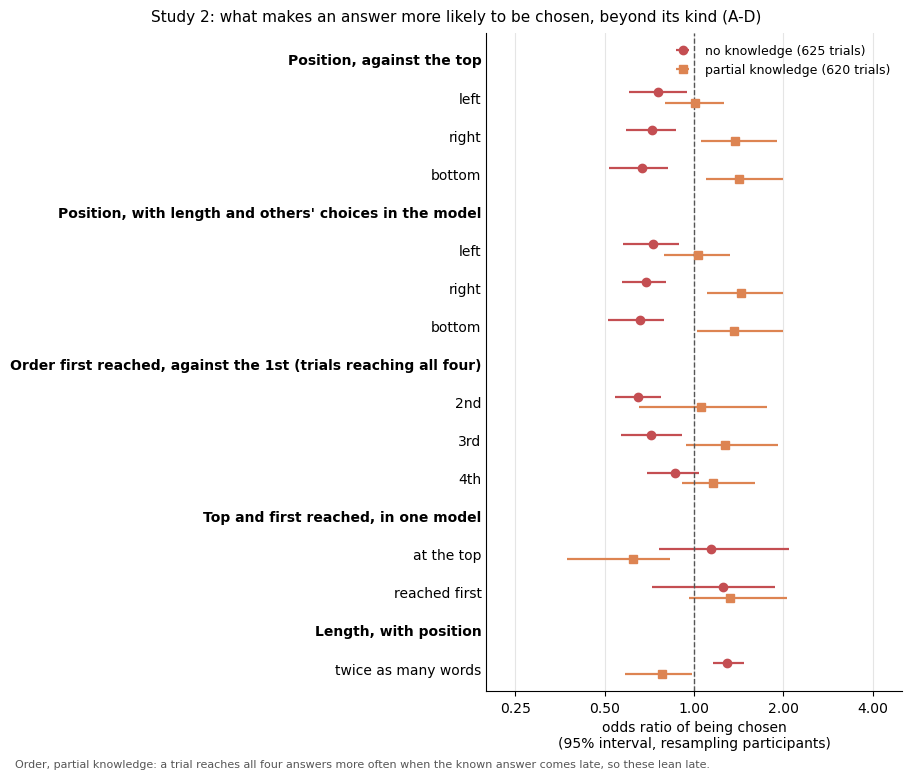

,subset,model,term,odds_ratio,ci_low,ci_high,p_boot,n_trials
3,no knowledge,position,position_left,0.757,0.605,0.946,0.014,625
4,no knowledge,position,position_right,0.721,0.589,0.867,0.000,625
5,no knowledge,position,position_bottom,0.668,0.519,0.819,0.000,625
9,no knowledge,order,reached_2nd,0.647,0.542,0.776,0.000,582
10,no knowledge,order,reached_3rd,0.714,0.566,0.911,0.007,582
11,no knowledge,order,reached_4th,0.860,0.696,1.035,0.140,582
15,no knowledge,top_and_first,at_top,1.139,0.762,2.081,0.684,625
16,no knowledge,top_and_first,reached_first,1.252,0.719,1.874,0.315,625
20,no knowledge,length,position_left,0.755,0.603,0.943,0.010,625
21,no knowledge,length,position_right,0.715,0.585,0.856,0.000,625


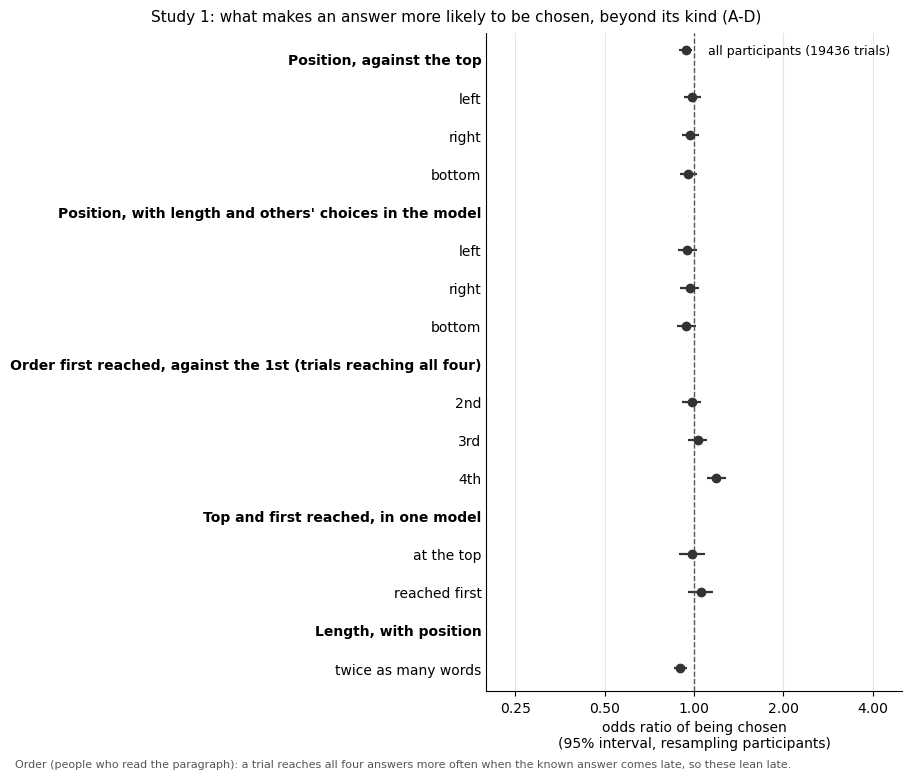

,subset,model,term,odds_ratio,ci_low,ci_high,p_boot,n_trials
3,all participants,position,position_left,0.986,0.925,1.053,0.730,19436
4,all participants,position,position_right,0.972,0.908,1.043,0.444,19436
5,all participants,position,position_bottom,0.955,0.894,1.022,0.198,19436
9,all participants,order,reached_2nd,0.984,0.911,1.053,0.694,15243
10,all participants,order,reached_3rd,1.030,0.956,1.109,0.428,15243
11,all participants,order,reached_4th,1.189,1.109,1.277,0.001,15243
15,all participants,top_and_first,at_top,0.985,0.892,1.089,0.774,19411
16,all participants,top_and_first,reached_first,1.052,0.957,1.161,0.298,19411
20,all participants,length,position_left,0.988,0.927,1.055,0.788,19436
21,all participants,length,position_right,0.973,0.909,1.044,0.472,19436


In [6]:
for key in STUDIES:
    P.plot_models(t[key], key)
    plt.show()
    m = t[key]["models"]
    display(m[~m["term"].str.startswith("kind")][["subset", "model", "term", "odds_ratio", "ci_low", "ci_high",
                                                   "p_boot", "n_trials"]].round(3))

## 6. What the eyes do with each position
*`scan.first_look_table`, `scan.gaze_table`, `scan.returns_table`, `scan.usual_starts`, `plots.plot_scan`*

One line per group:

* **(a)** where the first look at an answer lands;
* **(b)** each position's share of the gaze on the answers *not* chosen;
* **(c)** visits to each position per trial;
* **(d)** where the eyes land when they come back down from the question, after the opening look.

The tables: each participant's **usual first look** -- the position their first look lands on most
often, over all their trials -- with their dominant starting strategy; and, per group, how often
their choices went to the top, to their usual first look and to the first answer reached. A usual
first look counts only when it leads the runner-up by at least two trials, so no single trial decides
it; the test of choices at the usual first look is then exact.

**What to look for.** Whether the top answer's extra gaze is the same in every group. If it is, the
extra gaze alone cannot be what moves the choice -- it would have to matter only when nothing else
does.

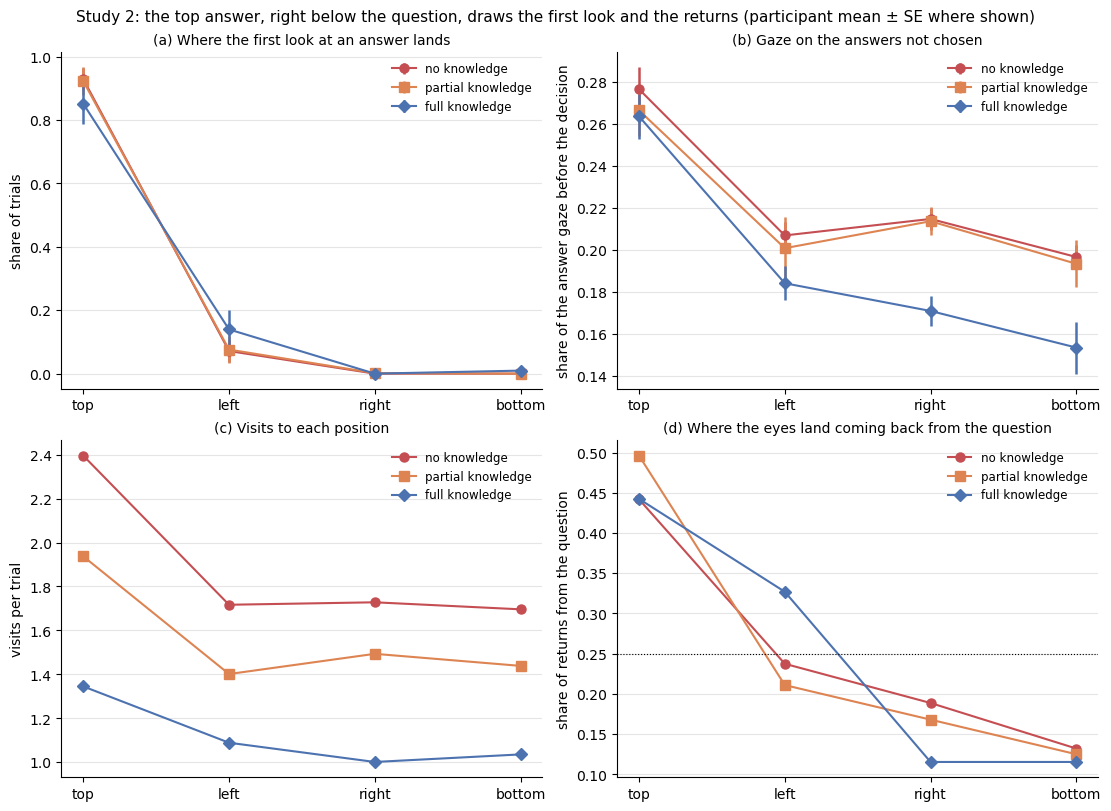

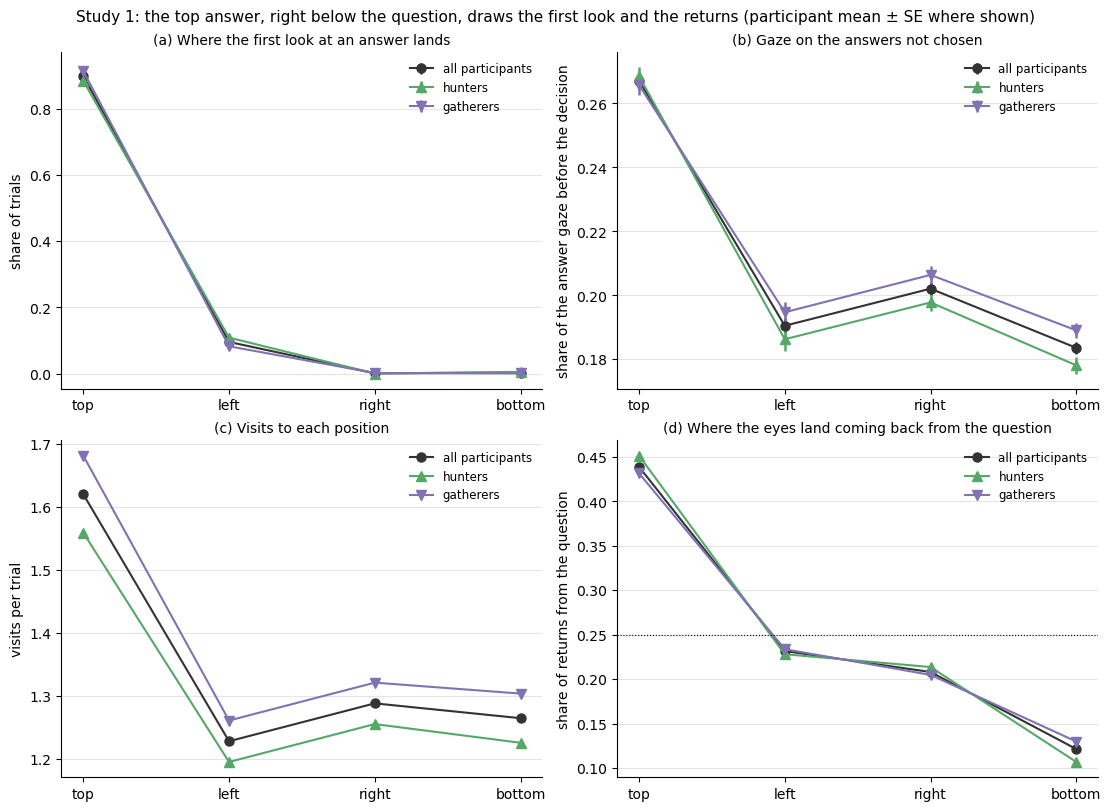

first_position,participant_id,n_first_top,n_first_left,n_first_right,n_first_bottom,usual_start,usual_start_share,usual_start_lead,dominant_strategy,dominance_score,n_strategy_trials
0,4000,129,12,0,4,top,0.890,117,top → left → right → bottom,0.462,145
1,4001,145,0,0,0,top,1.000,145,top → right → bottom → left,0.717,145
2,4002,142,3,0,0,top,0.979,139,top → right → bottom → left,0.276,145
3,4003,108,37,0,0,top,0.745,71,top → right → bottom → left,0.276,145
4,4004,135,10,0,0,top,0.931,125,top → left → bottom → right,0.255,145
5,4005,145,0,0,0,top,1.000,145,top → left → bottom → right,0.379,145
6,4006,144,1,0,0,top,0.993,143,top → right → bottom → left,0.476,145
7,4007,142,3,0,0,top,0.979,139,top → right → bottom → left,0.414,145
8,4008,144,1,0,0,top,0.993,143,top → right → bottom → left,0.655,145
9,4009,136,8,1,0,top,0.938,128,top → right → bottom → left,0.579,145


,participant_id,usual_start,n_trials,share_started_at_usual_start,share_chose_top,share_chose_usual_start,share_chose_first_reached,subset
0,4000,top,50,0.980,0.300,0.300,0.300,no knowledge
1,4001,top,50,1.000,0.420,0.420,0.420,no knowledge
2,4002,top,50,0.980,0.320,0.320,0.320,no knowledge
3,4003,top,50,0.840,0.380,0.380,0.320,no knowledge
4,4004,top,50,0.960,0.280,0.280,0.300,no knowledge
5,4005,top,50,1.000,0.280,0.280,0.280,no knowledge
6,4006,top,46,1.000,0.391,0.391,0.391,no knowledge
7,4007,top,46,0.935,0.261,0.261,0.283,no knowledge
8,4008,top,46,1.000,0.261,0.261,0.261,no knowledge
9,4009,top,46,0.913,0.304,0.304,0.326,no knowledge


first_position,participant_id,n_first_top,n_first_left,n_first_right,n_first_bottom,usual_start,usual_start_share,usual_start_lead,dominant_strategy,dominance_score,n_strategy_trials
10,l11_525,17,1,1,35,bottom,0.648,18,bottom → right → top → left,0.185,54
26,l14_352,7,47,0,0,left,0.870,40,left → top → right → bottom,0.593,54
83,l22_53,26,28,0,0,left,0.519,2,left → top → right → bottom,0.241,54
87,l23_371,18,36,0,0,left,0.667,18,left → top → right → bottom,0.537,54
90,l24_105,11,43,0,0,left,0.796,32,left → top → right → bottom,0.370,54
98,l25_243,19,35,0,0,left,0.648,16,left → top → right → bottom,0.500,54
231,l45_415,10,44,0,0,left,0.815,34,left → bottom → right → top,0.204,54
241,l47_144,25,29,0,0,left,0.537,4,left → top → right → bottom,0.352,54
246,l48_140,12,42,0,0,left,0.778,30,left → top → right → bottom,0.593,54
311,l57_501,19,35,0,0,left,0.648,16,left → top → right → bottom,0.352,54


In [7]:
for key in STUDIES:
    P.plot_scan(t[key], key)
    plt.show()
display(t["knowqa"]["usual_starts"].round(3))
display(t["knowqa"]["usual_start_choices"].query("subset == 'no knowledge'").round(3))
display(t["l1"]["usual_starts"].query("usual_start != 'top'").round(3))

## 7. Both studies side by side
*`choice.top_summary`, `plots.plot_overview`*

Every condition in one figure, as means over participants: **(a)** the share of choices at the top;
**(b)** accuracy with the correct answer at the top, minus with it elsewhere; **(c)** on the answers
not chosen, the top answer's share of the gaze minus the other positions'. The p values in (a) and
(b) are the randomisation tests of section 3.

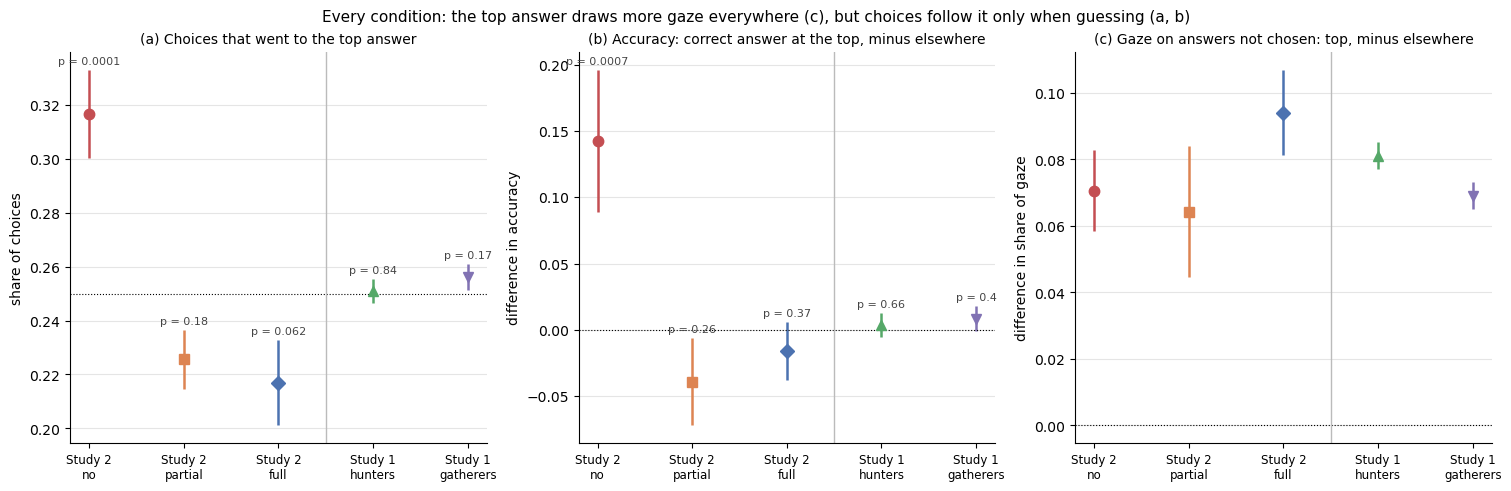

In [8]:
P.plot_overview(t)
plt.show()

## 8. Side findings
*`choice.kind_table`, `choice.length_table`, `scan.confidence_table`, `scan.speed_table`, `plots.plot_side`*

* **Which kind of answer was chosen.** Without the text, guessers do not spread evenly over the
  wrong answers.
* **Length.** How much longer the chosen answer is than its trial's average, in log2 words (1 means
  twice as long). The models of section 5 give the same, kind held fixed.
* **Confidence** (Study 2 only). Whether choices that went to the top answer were rated as more or
  less sure than the rest.
* **A trap: choices at the top by speed.** The share of choices at the top in each third of the
  participant's own decision times. Fast choices go to the top more often -- but the time it takes to
  reach an answer is part of the decision time, so an answer reached first is over-represented among
  fast choices even with no pull towards it at all. Study 1 shows exactly this pattern, strongly,
  while showing no pull to the top overall. So this split cannot test whether the first answer gets
  a head start, and is kept here to say so.

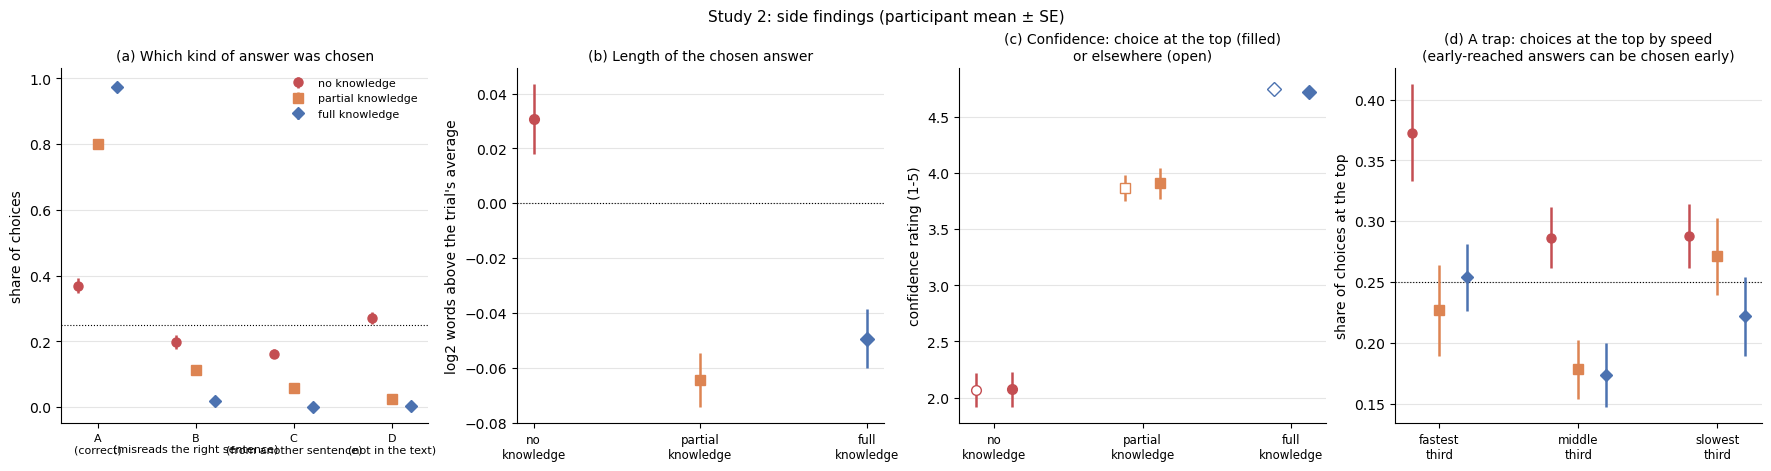

,subset,test,n_trials,statistic,df,p
0,no knowledge,choices at the top: the same share in each thi...,625,4.6304,2,0.0987
1,partial knowledge,choices at the top: the same share in each thi...,620,4.9872,2,0.0826
2,full knowledge,choices at the top: the same share in each thi...,640,4.1010,2,0.1287


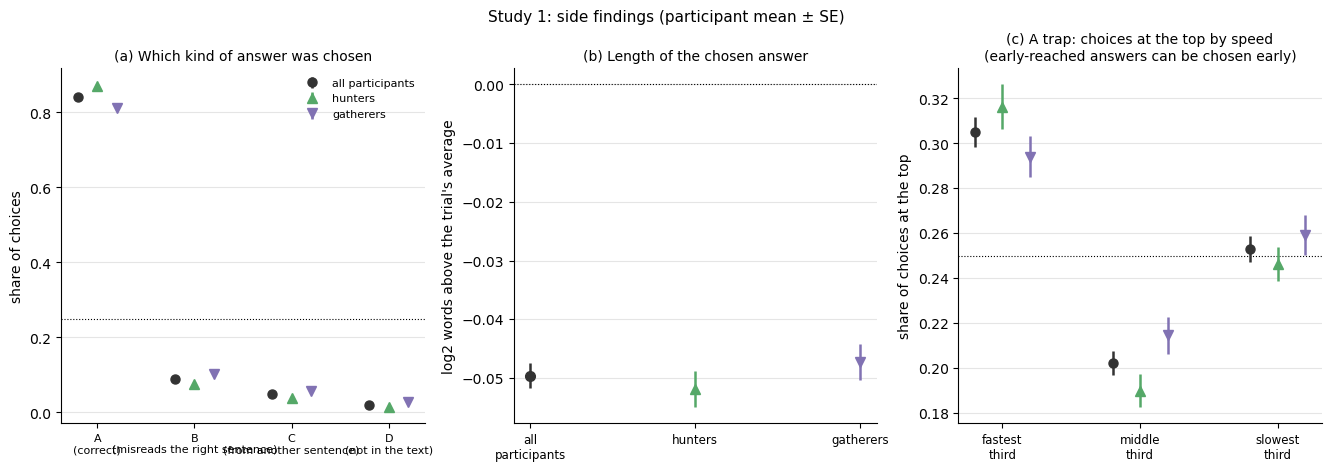

,subset,test,n_trials,statistic,df,p
0,all participants,choices at the top: the same share in each thi...,19411,181.0823,2,0.0
1,hunters,choices at the top: the same share in each thi...,9709,138.0679,2,0.0
2,gatherers,choices at the top: the same share in each thi...,9702,53.7940,2,0.0


,subset,test,n_trials,n_participants,statistic,p
0,no knowledge,confidence: the same whether or not the top an...,625,13,37.0,0.5879
1,no knowledge,confidence: the same whether or not the first ...,625,13,33.0,0.4143
2,partial knowledge,confidence: the same whether or not the top an...,620,13,36.0,0.5417
3,partial knowledge,confidence: the same whether or not the first ...,620,13,41.0,0.7869
4,full knowledge,confidence: the same whether or not the top an...,640,13,35.0,0.4973
5,full knowledge,confidence: the same whether or not the first ...,640,13,23.0,0.2334


In [9]:
for key in STUDIES:
    P.plot_side(t[key], key)
    plt.show()
    display(t[key]["speed_tests"].round(4))
display(t["knowqa"]["confidence_tests"].round(4))

## 9. What this can and cannot say

* **Exact for "position makes no difference".** The randomisation tests assume nothing about the
  answers or the people, only that the placement was random -- which section 2 checks.
* **The top answer and the first answer reached cannot be told apart.** Nearly every scan starts at
  the top in both studies, so the two are nearly always the same answer; the models that hold both
  say so. Study 1 has more trials that start elsewhere, but no pull to separate.
* **Small sample in Study 2.** Thirteen participants. The randomisation tests do not depend on that,
  but the intervals of the models do.
* **Gaze and choice.** Where the eyes go is measured, not assigned, so a link between the top
  answer's gaze and its choice does not by itself say which drives which. The placement is assigned,
  which is why the position tests are the firm part.

Main conclusions

When guessing, people favour the top answer. In Study 2’s no-knowledge regime, the answer just below the question is chosen 32% of the time instead of 25%. None of 10,000 random re-placements of the answers did as well (p ≤ 0.0001), and 12 of 13 people show it. It appears in wrong guesses (30% at the top, p = 0.04) and in right ones. Guesses are right 48% of the time when the correct answer happens to be at the top, against 29–39% elsewhere (p < 0.001).
It’s not an accident of where answers were placed. The correct answer wasn’t put at the top more often than chance, and neither was any answer type, long answers, or answers other people tended to choose. Content alone would send about 25–26% of guesses to the top. With answer type, length and another person’s choice all in the model, the top still wins: other positions have 0.66–0.73 times its odds.
There’s an order effect. The first answer reached is chosen most (31%), the second and third least (20% and 23%), and the fourth a little more (26%).
“Seen first” and “on top” can’t be separated. The first look lands on the top answer on 93% of guesses. 12 of 13 people in Study 2, and 348 of 360 in Study 1, start there by habit. Knowing each person’s own start point adds nothing beyond “the top answer”.
It only happens without knowledge. There’s no pull to the top with partial or full knowledge in Study 2. There’s none in Study 1 either (19,436 trials): 25.4% of choices at the top, accuracy the same wherever the correct answer sat, and odds ratios between 0.94 and 1.05.
Gaze favours the top answer everywhere, but choices follow it only when guessing. In every condition of both studies, the top answer gets 6–9 points more of the gaze, even when it isn’t chosen. Much of that comes from re-reading: 44% of the looks back down from the question land on it. This fits the idea that gaze tips the choice only when nothing else separates the options. Gaze isn’t assigned, though, so it can’t prove which way the influence runs.

Side findings

Guessers prefer longer answers (1.3 times the odds per doubling of length). People who’ve read the paragraph lean slightly the other way.
Guesses aren’t spread evenly: correct answer 37%, D 27%, B 20%, C 16%. Two people guessing the same item agree more than chance, so the answers carry content cues even without the text.
Choosing the top answer has nothing to do with confidence.
With partial knowledge, wrong answers lean to the right and bottom, away from the top (p = 0.002, from 124 errors). That’s unexplained, and only partly due to where the most tempting wrong answer happened to be placed.
A correction to something I said earlier: “more top choices on fast decisions” is not evidence of a head start for the first answer. Study 1 shows the same pattern strongly with no bias at all, because an answer reached early can simply be chosen early.

Caveats: Study 2 has only 13 participants. The position tests don’t depend on that, because the answer placement was random, but the model intervals do.